# tnia-ops and scikit-ops together

tnia-ops is a collection of ops with no runner of its own. Here scikit-ops'
runner runs ops from both collections in one pipeline, each in its own
environment:

1. **tnia-ops** draws random circles
2. **scikit-ops** blurs them
3. **tnia-ops** thresholds
4. **tnia-ops** fills holes

In [1]:
import matplotlib.pyplot as plt

import oprunner
from skop.ops.smooth import gaussian
from tnia_ops.morphology import fill_holes
from tnia_ops.segment import local_global_threshold
from tnia_ops.simulation import random_circles

## Where each op runs

Asking builds nothing.

In [2]:
steps = [random_circles, gaussian, local_global_threshold, fill_holes]

with oprunner.Runner() as runner:
    for op in steps:
        env = runner.env_for(op)
        print(f"{op.__module__}:{op.__name__}")
        print(f"    environment: {env.id}")
        print(f"    defined in:  {env.config}")
        print(f"    built in:    {env.folder}")

tnia_ops.simulation:random_circles
    environment: numpy_1x
    defined in:  /home/bnorthan/code/i2k/tnia/tnia-ops/envs/numpy_1x/pixi.toml
    built in:    /home/bnorthan/.local/share/appose/tnia-numpy-1x
skop.ops.smooth:gaussian
    environment: skimage
    defined in:  /home/bnorthan/code/i2k/tnia/scikit-ops/envs/skimage/pixi.toml
    built in:    /home/bnorthan/.local/share/appose/skop-skimage
tnia_ops.segment:local_global_threshold
    environment: skimage
    defined in:  /home/bnorthan/code/i2k/tnia/tnia-ops/envs/skimage/pixi.toml
    built in:    /home/bnorthan/.local/share/appose/tnia-skimage
tnia_ops.morphology:fill_holes
    environment: skimage
    defined in:  /home/bnorthan/code/i2k/tnia/tnia-ops/envs/skimage/pixi.toml
    built in:    /home/bnorthan/.local/share/appose/tnia-skimage


Two environments are called `skimage`, one from each collection. Each is built,
and run, as itself.

## The pipeline

In [3]:
with oprunner.Runner() as runner:
    circles = runner.run(random_circles, height=256, width=256, count=15, seed=1)
    blurred = runner.run(gaussian, image=circles, sigma=3.0)
    labels = runner.run(local_global_threshold, image=blurred, window=51, global_threshold=50)
    filled = runner.run(fill_holes, labels=labels)

for name, image in [("circles", circles), ("blurred", blurred), ("labels", labels), ("filled", filled)]:
    print(f"{name:8s} {image.dtype}, min {image.min():.1f}, max {image.max():.1f}")

circles  float32, min 0.0, max 1077.0
blurred  float32, min 0.0, max 897.8
labels   int32, min 0.0, max 14.0
filled   int32, min 0.0, max 14.0


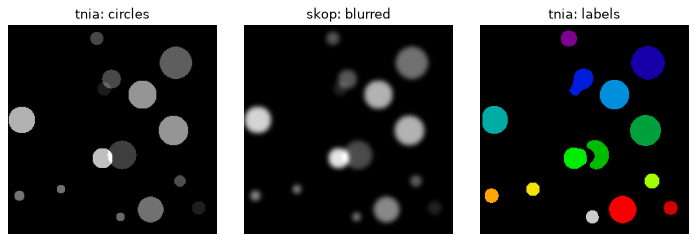

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3), dpi=80)
for ax, (title, image) in zip(axes, [("tnia: circles", circles), ("skop: blurred", blurred), ("tnia: labels", filled)]):
    ax.imshow(image, cmap="nipy_spectral" if title.endswith("labels") else "gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()